## Data Preprocessing with Scanpy

In [31]:
# Core scverse libraries
from __future__ import annotations

import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import math
import os

In [32]:
# Set verbosity to see more log output
sc.settings.verbosity = 4

### Reading in Data from spleen droplet folder(s) into an AnnData object

In [33]:
# Load data from 10X Genomics format directory using scanpys read_10x_mtx function


# sc.read_10x_mtx("droplet/Spleen-10X_P4_7"),
# sc.read_10x_mtx("droplet/Spleen-10X_P7_6"),

# checking how visualizations look when spleen_droplet_annotation.csv used for cell type labels instead of annotations_droplet.csv

tiss = ad.concat([
    sc.read_10x_mtx("../droplet/Spleen-10X_P4_7"),
    sc.read_10x_mtx("../droplet/Spleen-10X_P7_6"),
])

tiss.obs_names_make_unique()

tiss.obs


    reading ../droplet/Spleen-10X_P4_7/matrix.mtx
--> This might be very slow. Consider passing `cache=True`, which enables much faster reading from a cache file.
    reading ../droplet/Spleen-10X_P7_6/matrix.mtx
--> This might be very slow. Consider passing `cache=True`, which enables much faster reading from a cache file.


/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/anndata/_core/anndata.py:1792: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


""
AAACCTGAGAAGGACA-1
AAACCTGAGCTAAGAT-1
AAACCTGCAACAACCT-1
AAACCTGCAGCCAATT-1
AAACCTGCAGCTCCGA-1
...
TTTGTCAGTTTGCATG-1
TTTGTCATCAAACCAC-1
TTTGTCATCGTGACAT-1
TTTGTCATCTCAACTT-1


In [34]:
tiss.obs

""
AAACCTGAGAAGGACA-1
AAACCTGAGCTAAGAT-1
AAACCTGCAACAACCT-1
AAACCTGCAGCCAATT-1
AAACCTGCAGCTCCGA-1
...
TTTGTCAGTTTGCATG-1
TTTGTCATCAAACCAC-1
TTTGTCATCGTGACAT-1
TTTGTCATCTCAACTT-1


### Quality Control using Organ Annotation Vignette that described quality control steps done in the study 
https://static-content.springer.com/esm/art%3A10.1038%2Fs41586-018-0590-4/MediaObjects/41586_2018_590_MOESM4_ESM.pdf

In [35]:
sc.pp.filter_cells(tiss, min_genes=500)
sc.pp.filter_cells(tiss, min_counts=1000)

tiss.obs

filtered out 21 cells that have less than 500 genes expressed


,n_genes,n_counts
AAACCTGAGAAGGACA-1,1143,2970.0
AAACCTGAGCTAAGAT-1,1229,2851.0
AAACCTGCAACAACCT-1,1161,2869.0
AAACCTGCAGCCAATT-1,1272,3874.0
AAACCTGCAGCTCCGA-1,1727,7628.0
...,...,...
TTTGTCAGTTTGCATG-1,1388,3846.0
TTTGTCATCAAACCAC-1,1115,2740.0
TTTGTCATCGTGACAT-1,1127,2267.0
TTTGTCATCTCAACTT-1,1009,3543.0


## Normalization

In [36]:
# Normalizing to median total counts
sc.pp.normalize_total(tiss, target_sum=1e4)

# Logarithmize the data
sc.pp.log1p(tiss)

# Scale (center to 0, unit variance)
sc.pp.scale(tiss)


normalizing counts per cell
    finished (0:00:00)


/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


## Feature Selection
By including only the most informative genes. The genes that vary the most in the data.

In [37]:
sc.pp.highly_variable_genes(tiss, flavor="seurat", max_mean=math.inf, min_disp=0.5)

extracting highly variable genes
    finished (0:00:02)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)


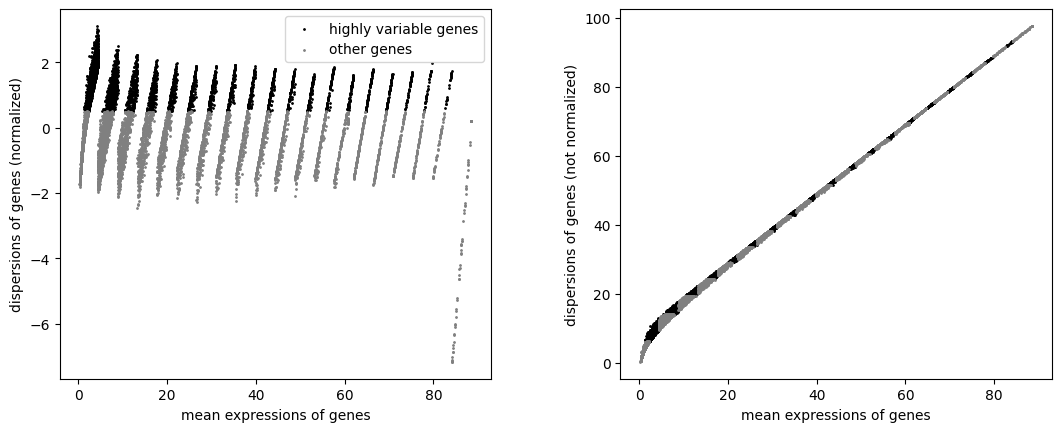

In [38]:
sc.pl.highly_variable_genes(tiss)

In [39]:
# Keep only HVGs
tiss = tiss[:, tiss.var.highly_variable]

tiss.var

,mean,std,highly_variable,means,dispersions,dispersions_norm
St18,0.000158,0.011222,True,74.642152,83.806658,1.280777
Adhfe1,0.000916,0.032833,True,39.031902,47.798217,0.958150
2610203C22Rik,0.000157,0.011137,True,73.998252,83.162758,0.810152
Ppp1r42,0.000515,0.027749,True,57.179284,66.301418,1.550747
Sulf1,0.000496,0.028443,True,56.745509,65.908706,1.251800
...,...,...,...,...,...,...
Tlr7,0.055493,0.263906,True,2.385412,7.137801,0.830394
Arhgap6,0.015946,0.141110,True,7.048753,14.428286,0.630847
Amelx,0.000325,0.022817,True,70.671832,79.836337,1.575138
G530011O06Rik,0.005110,0.079607,True,16.189716,24.616365,0.559331


## Dimensionality Reduction
Through PCA

In [40]:
# PCA
sc.pp.pca(tiss)


computing PCA
    with n_comps=50
    finished (0:00:02)
    and added
    'X_pca', the PCA coordinates (adata.obs)
    'PCs', the loadings (adata.varm)
    'pca_variance', the variance / eigenvalues (adata.uns['pca'])
    'pca_variance_ratio', the variance ratio (adata.uns['pca'])


/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/scanpy/preprocessing/_pca/__init__.py:384: ImplicitModificationWarning: Setting element `.obsm['X_pca']` of view, initializing view as actual.
  adata.obsm[key_obsm] = x_pca


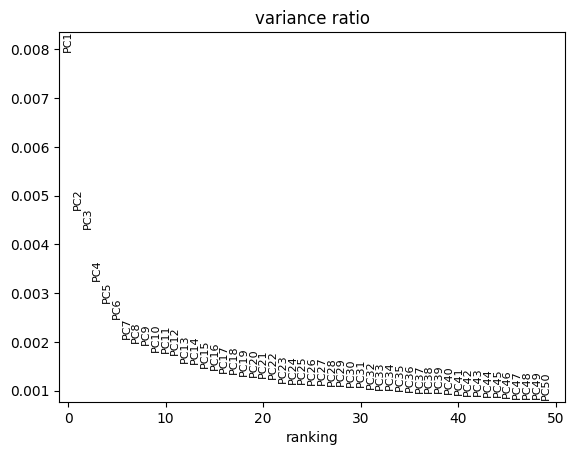

In [41]:
sc.pl.pca_variance_ratio(tiss, n_pcs=50)

## reading in annotations


In [42]:
spleen_annotations = pd.read_csv("../annotations/Spleen_droplet_annotation.csv")

y = spleen_annotations["cell_ontology_class"].values
y


array(['B cell', 'natural killer cell', 'B cell', ..., 'B cell', 'T cell',
       'macrophage'], shape=(9552,), dtype=object)

In [43]:
tiss.obs["cell_ontology_class"] = y
tiss.obs

,n_genes,n_counts,cell_ontology_class
AAACCTGAGAAGGACA-1,1143,2970.0,B cell
AAACCTGAGCTAAGAT-1,1229,2851.0,natural killer cell
AAACCTGCAACAACCT-1,1161,2869.0,B cell
AAACCTGCAGCCAATT-1,1272,3874.0,B cell
AAACCTGCAGCTCCGA-1,1727,7628.0,B cell
...,...,...,...
TTTGTCAGTTTGCATG-1,1388,3846.0,B cell
TTTGTCATCAAACCAC-1,1115,2740.0,B cell
TTTGTCATCGTGACAT-1,1127,2267.0,B cell
TTTGTCATCTCAACTT-1,1009,3543.0,T cell


## Clustering


In [44]:
# Compute t-SNE
sc.pp.neighbors(tiss, n_neighbors=15, n_pcs=10)

# below to mimic organ vignette supplementary preprocessing steps (using R, Seurat for FindClusters)
sc.tl.louvain(tiss, resolution=0.4) 

computing neighbors
    computing neighbors
    using 'X_pca' with n_pcs = 10
    computed neighbors (0:00:00)
    computed connectivities (0:00:00)
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
running Louvain clustering
    using the "louvain" package of Traag (2017)
    finished: found 7 clusters and added
    'louvain', the cluster labels (adata.obs, categorical) (0:00:00)


In [45]:
#inspection based on above ouptput
tiss.obs

,n_genes,n_counts,cell_ontology_class,louvain
AAACCTGAGAAGGACA-1,1143,2970.0,B cell,0
AAACCTGAGCTAAGAT-1,1229,2851.0,natural killer cell,4
AAACCTGCAACAACCT-1,1161,2869.0,B cell,1
AAACCTGCAGCCAATT-1,1272,3874.0,B cell,0
AAACCTGCAGCTCCGA-1,1727,7628.0,B cell,0
...,...,...,...,...
TTTGTCAGTTTGCATG-1,1388,3846.0,B cell,1
TTTGTCATCAAACCAC-1,1115,2740.0,B cell,1
TTTGTCATCGTGACAT-1,1127,2267.0,B cell,1
TTTGTCATCTCAACTT-1,1009,3543.0,T cell,2


## Visualizing Clusters Using tSNE

computing tSNE
    using 'X_pca' with n_pcs = 10
    using sklearn.manifold.TSNE
[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 9552 samples in 0.002s...
[t-SNE] Computed neighbors for 9552 samples in 0.474s...
[t-SNE] Computed conditional probabilities for sample 1000 / 9552
[t-SNE] Computed conditional probabilities for sample 2000 / 9552
[t-SNE] Computed conditional probabilities for sample 3000 / 9552
[t-SNE] Computed conditional probabilities for sample 4000 / 9552
[t-SNE] Computed conditional probabilities for sample 5000 / 9552
[t-SNE] Computed conditional probabilities for sample 6000 / 9552
[t-SNE] Computed conditional probabilities for sample 7000 / 9552
[t-SNE] Computed conditional probabilities for sample 8000 / 9552
[t-SNE] Computed conditional probabilities for sample 9000 / 9552
[t-SNE] Computed conditional probabilities for sample 9552 / 9552
[t-SNE] Mean sigma: 0.545610
[t-SNE] KL divergence after 250 iterations with early exaggeration: 85.773438
[t-SNE] KL 

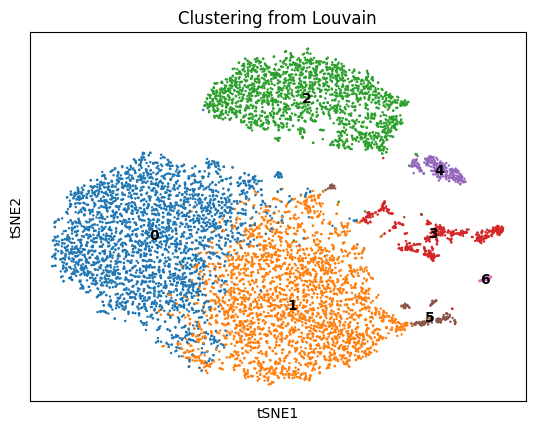

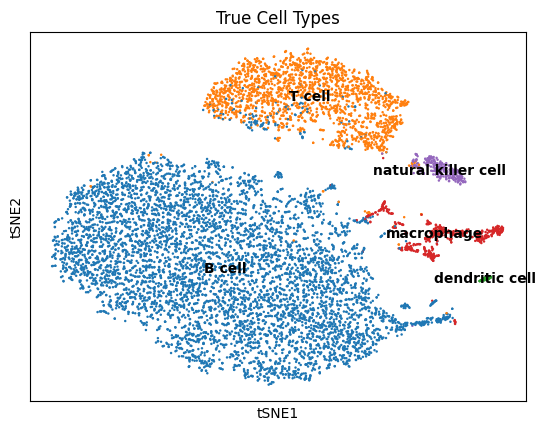

In [46]:
#computer tSNE
sc.tl.tsne(tiss, n_pcs=10, perplexity=30, random_state=0)

# Plot tSNE
sc.pl.tsne(tiss, color="louvain", title="Clustering from Louvain", legend_loc='on data')

# Plot tSNE
sc.pl.tsne(tiss, color="cell_ontology_class", title="True Cell Types", legend_loc='on data')


## Machine Learning related preprocessing

In [47]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler


# Encode labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Train-test split
X_train, X_test, Y_train, Y_test = train_test_split(
    tiss.X, y_encoded, test_size=0.2, random_state=42
)

X_train.shape, X_test.shape, Y_train.shape, Y_test.shape

((7641, 4590), (1911, 4590), (7641,), (1911,))

## scikit-learn Machine Learning Classifiers

In [48]:
# --- CLASSIFIERS ---
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

# optional xgboost support
try:
    from xgboost import XGBClassifier
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBOOST_AVAILABLE = False

In [49]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVM (RBF Kernel)": SVC(probability=True),
    "Random Forest": RandomForestClassifier(n_estimators=200),
    "Gradient Boosting": GradientBoostingClassifier(),
    "KNN (k=5)": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB()
}

In [50]:
from sklearn.metrics import classification_report, accuracy_score

# Train + evaluate each model
for name, model in models.items():
    model.fit(X_train, Y_train)
    preds = model.predict(X_test)
    acc = accuracy_score(Y_test, preds)

    print("=" * 60)
    print(f"📌 Model: {name}")
    print(f"✅ Accuracy: {acc:.4f}")
    print("\nClassification Report:")
    print(classification_report(Y_test, preds))

📌 Model: Logistic Regression
✅ Accuracy: 0.9833

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99      1403
           1       0.95      0.99      0.97       358
           2       1.00      1.00      1.00         8
           3       0.94      0.99      0.96        95
           4       0.94      0.98      0.96        47

    accuracy                           0.98      1911
   macro avg       0.96      0.99      0.98      1911
weighted avg       0.98      0.98      0.98      1911

📌 Model: SVM (RBF Kernel)
✅ Accuracy: 0.9623

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.99      0.98      1403
           1       0.95      0.96      0.95       358
           2       0.00      0.00      0.00         8
           3       0.99      0.79      0.88        95
           4       1.00      0.72      0.84        47

    accuracy                           0.96 

/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

📌 Model: Random Forest
✅ Accuracy: 0.9780

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      1403
           1       0.94      0.97      0.95       358
           2       1.00      1.00      1.00         8
           3       0.98      0.95      0.96        95
           4       0.98      0.96      0.97        47

    accuracy                           0.98      1911
   macro avg       0.98      0.97      0.97      1911
weighted avg       0.98      0.98      0.98      1911

📌 Model: Gradient Boosting
✅ Accuracy: 0.9634

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98      1403
           1       0.95      0.89      0.92       358
           2       0.89      1.00      0.94         8
           3       0.98      0.91      0.94        95
           4       0.96      0.96      0.96        47

    accuracy                           0.96      

/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

📌 Model: Naive Bayes
✅ Accuracy: 0.3752

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.25      0.39      1403
           1       0.36      0.82      0.51       358
           2       1.00      0.25      0.40         8
           3       0.10      0.63      0.17        95
           4       0.10      0.11      0.10        47

    accuracy                           0.38      1911
   macro avg       0.47      0.41      0.31      1911
weighted avg       0.67      0.38      0.39      1911



## Pytorch Neural Network

In [51]:
import torch
from torch.utils.data import Dataset, DataLoader

# Normalize and scale
# scaler = StandardScaler(with_mean=False)
# X_scaled = scaler.fit_transform(X)
# commented out because data is already normalized and scaled using scanpy

# Convert to torch tensors
# train
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(Y_train, dtype=torch.long)
# test
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(Y_test, dtype=torch.long)



In [52]:
class SingleCellDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

dataset = SingleCellDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(dataset, batch_size=128, shuffle=True)


In [53]:
import torch.nn as nn
import torch.nn.functional as F

class Classifier(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, 10)
        self.fc2 = nn.Linear(10, 10)
        self.fc3 = nn.Linear(10, num_classes)
        # self.dropout = nn.Dropout(0.3)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        # x = self.dropout(x)
        x = F.relu(self.fc2(x))
        # x = self.dropout(x)
        x = self.fc3(x)
        return x


In [54]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = Classifier(input_dim=X_train_tensor.shape[1], num_classes=len(le.classes_)).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

for epoch in range(10):
    model.train()
    total_loss = 0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    print(f"Epoch {epoch+1}, Loss: {total_loss/len(train_loader):.4f}")


Epoch 1, Loss: 0.8173
Epoch 2, Loss: 0.1540
Epoch 3, Loss: 0.0614
Epoch 4, Loss: 0.0326
Epoch 5, Loss: 0.0214
Epoch 6, Loss: 0.0165
Epoch 7, Loss: 0.0139
Epoch 8, Loss: 0.0113
Epoch 9, Loss: 0.0079
Epoch 10, Loss: 0.0057


In [55]:
model.eval()
with torch.no_grad():
    y_test_pred = model(X_test_tensor.to(device)).argmax(dim=1).cpu().numpy()

acc = accuracy_score(Y_test, y_test_pred)

print("=" * 60)
print(f"📌 Model: Neural Network")
print(f"✅ Accuracy: {acc:.4f}")
print("\nClassification Report:")
print(classification_report(Y_test, y_test_pred))


📌 Model: Neural Network
✅ Accuracy: 0.9812

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1403
           1       0.96      0.97      0.97       358
           2       0.80      1.00      0.89         8
           3       0.99      0.91      0.95        95
           4       0.85      0.98      0.91        47

    accuracy                           0.98      1911
   macro avg       0.92      0.97      0.94      1911
weighted avg       0.98      0.98      0.98      1911



## Visualizing Model Results using TSNE

In [56]:

model.eval()
with torch.no_grad():
    preds = model(torch.tensor(tiss.X, dtype=torch.float32).to(device))
    tiss.obs["nn_pred"] = preds.argmax(1).cpu().numpy()


In [57]:
tiss.obs["nn_pred_label"] = le.inverse_transform(tiss.obs["nn_pred"])


In [58]:
import scanpy as sc

# Compute t-SNE
sc.pp.neighbors(tiss, n_neighbors=15, n_pcs=10)

# below to mimic organ vignette supplementary preprocessing steps (using R, Seurat for FindClusters)
sc.tl.leiden(tiss, resolution=3.5) 


sc.tl.tsne(tiss, n_pcs=10, perplexity=30, random_state=0)



computing neighbors
        initialized `.distances` `.connectivities` 
    computing neighbors
    using 'X_pca' with n_pcs = 10
    computed neighbors (0:00:00)
    computed connectivities (0:00:00)
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
running Leiden clustering
    finished: found 50 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:03)
computing tSNE
    using 'X_pca' with n_pcs = 10
    using sklearn.manifold.TSNE
[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 9552 samples in 0.002s...
[t-SNE] Computed neighbors for 9552 samples in 0.475s...
[t-SNE] Computed conditional probabilities for sample 1000 / 9552
[t-SNE] Computed conditional probabilities for sample 2000 / 9552
[t-SNE] Computed conditional probabilities for sample 3000 / 9552
[t-SNE] Computed conditional probabilities for sample 4000 / 9552
[t-S

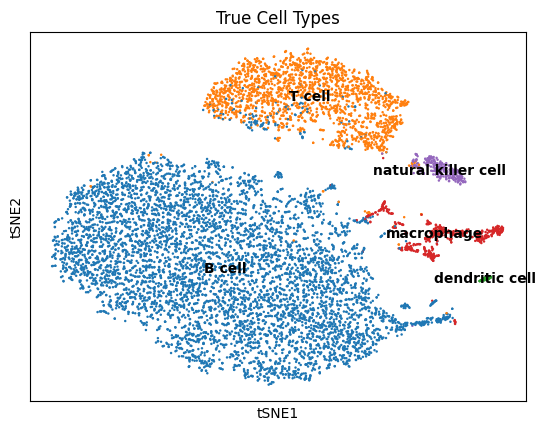

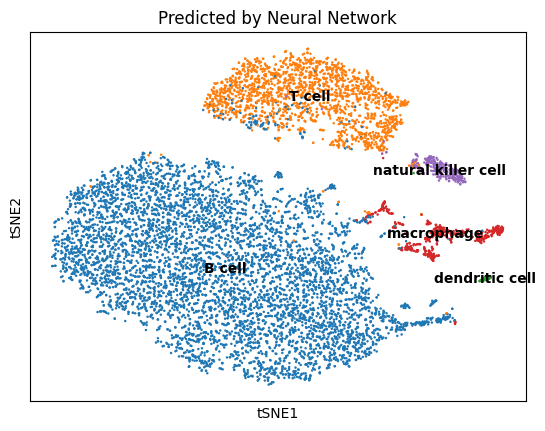

In [59]:
# True labels
sc.pl.tsne(tiss, color="cell_ontology_class", title="True Cell Types", legend_loc='on data')

# Predicted labels
sc.pl.tsne(tiss, color="nn_pred_label", title="Predicted by Neural Network", legend_loc='on data')


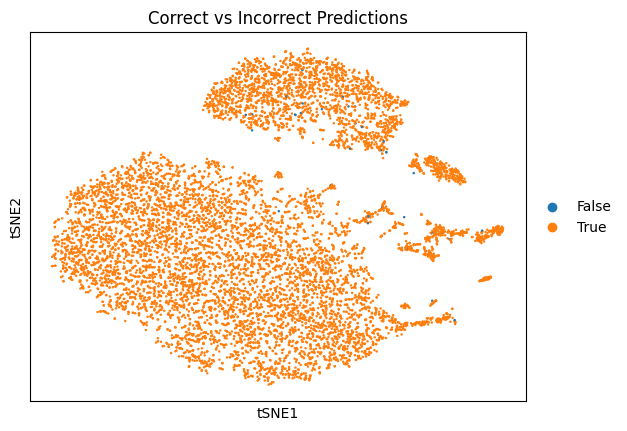

In [60]:
tiss.obs["correct"] = (tiss.obs["nn_pred_label"] == tiss.obs["cell_ontology_class"]).astype(str)
sc.pl.tsne(tiss, color="correct", title="Correct vs Incorrect Predictions")
